# Bonus: 3D Energy Surface

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/ch2B-A-optimizing-3Dpath.ipynb)
:::



In [1]:
#| label: setup-2BA
#| tags: [remove-cell, remove-stdout]

####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import rdkit
except ImportError:
    !pip -q install rdkit
    import rdkit

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    plt.style.use("styles/tufte.mplstyle")
    nproc = 4          # my own computer limit: 4 threads. Yours may vary. Adjust this number to your system's capabilities. Don't include efficiency cores as they are not well-suited for Psi4 calculations.

import psi4_helpers as ph

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output/ch2/2B-optimizing")
output_dir.mkdir(exist_ok=True)


# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
psi4.set_memory("2 GB")

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = True

  Threads set to 4 by Python driver.

  Memory set to   1.863 GiB by Python driver.


Earlier we [scanned one coordinate](ch2B-optimizing.ipynb#rigid-scan) with the angle held fixed. We could repeat that and vary only the bond angle. What if we varied both the bond lengths and angles? We would be able to find the lowest energy combination from the results. That would be very close to the final optimized structure.

## Optimization

In the [code below](#optimize-2), we will repeat the optimization performed previously. I could have saved those results in a data file, but its easy to perform the optimization calculation again, so I went with the copy and paste option.

In [11]:
#| label: optimize-2
#| tages: [remove-stdout, remove-stderr]
#| class: scroll-input

psi4.set_output_file(output_dir / "02B-opt-2.out", False) # all output files written to the output folder, but not printed to the notebook
psi4.set_options({"reference": "rhf",     # rhf (default), uhf, rohf, or cuhf
                  "scf_type": "pk"})       # SCF algorithm; the Psi4 default is "df"

# define the geometry of a water molecule in Z-matrix format
water = """
0 1                  # charge and multiplicity: 0 = neutral, 1 = singlet
H
O 1 1.0              # typical bond length for X-H bonds is 1.0 Å
H 2 1.0 1 109.0      # typical bond angle for sp3 is 109.0°
"""

mol = psi4.geometry(water)  # create a molecule object from the water geometry

print(f"Start:  r = {ph.bond_length(mol, 1, 2):.4f} Å     angle = {ph.bond_angle(mol, 3, 2, 1):.2f}°")

# optimize geometry and return the optimized energy, wavefunction, and optimization history
E_opt, wfn, history = psi4.optimize("hf/6-31g*",        
                                    molecule=mol, 
                                    return_wfn=True, 
                                    return_history=True
                                    )
print(f"Final:  r = {ph.bond_length(mol, 1, 2):.4f} Å     angle = {ph.bond_angle(mol, 3, 2, 1):.2f}°")
print(f"Final energy = {E_opt:.8f} hartree after {len(history['energy'])} steps")


Start:  r = 1.0000 Å     angle = 109.00°
Optimizer: Optimization complete!
Final:  r = 0.9472 Å     angle = 105.49°
Final energy = -76.01074647 hartree after 4 steps


## The Path to Perfection

In the **previous** notebook, we observed code that presented the [energy at each step](ch2B-optimizing.ipynb#plot-history) of the optimization. A list of energies and **geometries** is available in the `history` object returned by the `psi.optimize()` function. We can use the list of geometries (in *xyz* format) to calculate the **bond lengths and angles** at each step of the optimization. The [code below](#calc-path) will perform these calculations and report the results.

In [12]:
#| label: calc-path
#| class: scroll-input

# bond length and angle at each optimization step (history coordinates are in bohr)
path_r, path_angle = [], []
for coords in history["coordinates"]:
    xyz = np.asarray(coords) * psi4.constants.bohr2angstroms
    v1 = xyz[0] - xyz[1]                      # O -> H1  (atom order is H, O, H)
    v2 = xyz[2] - xyz[1]                      # O -> H2
    r1, r2 = np.linalg.norm(v1), np.linalg.norm(v2)
    path_r.append((r1 + r2) / 2)
    path_angle.append(np.degrees(np.arccos(np.dot(v1, v2) / (r1 * r2))))
path_E = (np.array(history["energy"]) - E_opt) * psi4.constants.hartree2kJmol

for n, (r, a, e) in enumerate(zip(path_r, path_angle, path_E), start=1):
    print(f"step {n}: r = {r:.4f} Å   angle = {a:6.2f}°   E = {e:6.2f} kJ/mol")

step 1: r = 1.0000 Å   angle = 109.00°   E =  15.76 kJ/mol
step 2: r = 0.9438 Å   angle = 103.56°   E =   0.40 kJ/mol
step 3: r = 0.9479 Å   angle = 105.64°   E =   0.00 kJ/mol
step 4: r = 0.9472 Å   angle = 105.49°   E =   0.00 kJ/mol


## The Second Dimension

Water has three internal coordinates, but because both O–H bonds stay equal during this optimization, we can describe every step with just **two** variables: the O–H **bond length** and the H–O–H **bond angle**. The [code below](#scan-2d) calculates the energy on a **grid** of lengths and angles, which maps out the **potential energy well**. The following cells draw the surface in 3D and as a contour map, and add the **path** the optimizer took, using the coordinates saved in `history`.

### Perform the Scan
The [code below](#scan-2d) creates an *x*,*y* grid of bond lengths and angles and caluclates the energy at every *x*,*y* pair. We now have a 2-dimensional scan of energy. 

```{note} Psi4 settings in this cell
:class: dropdown
`E_grid[i, j]`
: A 2D *NumPy* array: each row is one angle and each column is one bond length. Its a *x*,*y* grid and we will calculate the energy of the structure at each *x*,*y* pair. All energies are made relative to the optimized energy reported from the optimization of water (`E_opt`), so the bottom of the well is close to zero.
```

In [4]:
#| label: scan-2d
#| class: scroll-input

grid_size = 20     # nXn grid. set n to 20. can make larger but time will increase. 

psi4.set_output_file(output_dir / "02B-opt-2Dscan.out", False)  # write output to a file, not the notebook

r_values     = np.linspace(0.89, 1.01, grid_size)      # O-H bond lengths from 0.89 to 1.01 Å
angle_values = np.linspace(98.0, 114.0, grid_size)     # H-O-H angles from 98 to 114°

E_grid = np.zeros((len(angle_values), len(r_values)))   # rows = angles, columns = distances

for i, angle in enumerate(angle_values):        # loop over the angles...
    for j, r in enumerate(r_values):            # ...and, for each angle, over the distances
        # make a new Z-matrix for each combination of r and angle
        scan_mol = psi4.geometry(f"""           
        0 1
        H
        O 1 {r}
        H 2 {r} 1 {angle}
        """)
        E_grid[i, j] = psi4.energy("hf/6-31g*", molecule=scan_mol)

# relative energies in kJ/mol, measured from the optimized structure
rel_E_grid = (E_grid - E_opt) * psi4.constants.hartree2kJmol
print(f"{E_grid.size} energies calculated")

400 energies calculated


### A Contour Plot

We can **visualize** the energy at each point on the map using a **contour plot**. The [code below(2d-plot)] produces a contour plot that **describes** the energy at each *x,y* value for bond length and bond angle. 

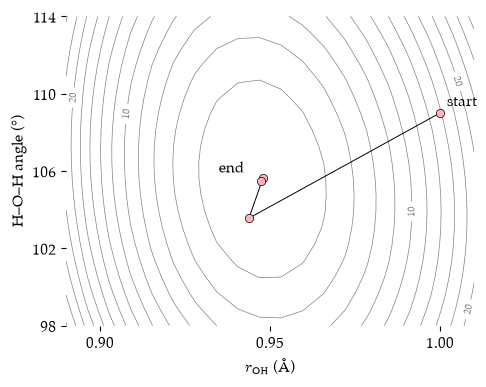

In [42]:
#| label: 2d-plot
#| class: scroll-input
#| caption: Contour plot of HF/6-31G* energy surface for water, with the optimization path shown.

fig, ax2d = plt.subplots(figsize=(5, 4))

# plot path of optimization
ax2d.plot(path_r, path_angle, color="black", linewidth=0.7, marker="o",
          markerfacecolor="#FFB3BA", markeredgecolor="black", markeredgewidth=0.5, zorder=2)
ax2d.annotate("start", (path_r[0], path_angle[0]), xytext=(5, 5), textcoords="offset points")
ax2d.annotate("end", (path_r[-1], path_angle[-1]), xytext=(-30, 6), textcoords="offset points")

# contour map (looking straight down on the surface)
levels = np.arange(0, rel_E_grid.max(), 2.0)
cs = ax2d.contour(R, A, rel_E_grid, levels=levels, colors="grey", linewidths=0.5, zorder=1)
ax2d.clabel(cs, levels[::5], fontsize=7, fmt="%.0f")

# style plot
ax2d.set_xlabel(r"$r_{\mathrm{OH}}$ (Å)")
ax2d.set_ylabel("H–O–H angle (°)")
ax2d.set_xticks([0.9,0.95,1.0])
ax2d.set_yticks([98,102,106,110,114])
#fig.suptitle("HF/6-31G* energy surface for water, with the optimization path")

# output plot
plt.savefig(output_dir / "02B-opt-2Dscan.png", dpi=300, bbox_inches="tight")
plt.show()

The four steps in the optimization are shown on the plot. The first step **overshoots**: it jumps from the start (1.00 Å, 109°) past the bottom of the well, to an angle that is a little too small. The next steps **correct** this and settle at the minimum (0.947 Å, 105.5°). 

You may **observe** in the contour plot that the surface has higher **curvature** along the *x*-axis (changing bond length), compared to the *y*-axis (changing bond angle). This fits with the observation that O–H bonds have higher **frequencies** of vibration for **stretching** compared to **bending**.

### A Third Dimension

The [code below](#3d-plot) produces a **3D plot** of the energy **surface** with the optimization **path** shown on that surface. This again highlights that the changes in **bond length** lead to a deeper energy well than changes in the **bond angle**.

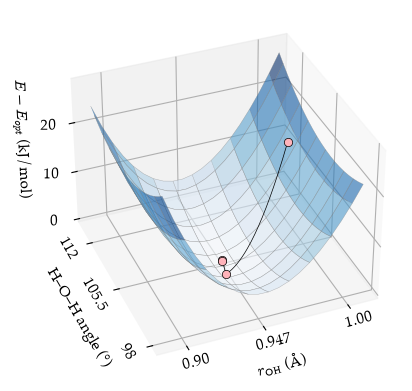

In [41]:
#| label: 3d-plot
#| class: scroll-input
#| caption: 3D plot of the HF/6-31G* energy surface for water, with the optimization path shown.

from scipy.interpolate import RegularGridInterpolator

# create 2D grids of x and y values to match E_grid
R, A = np.meshgrid(r_values, angle_values)    

# energy anywhere on the surface, interpolated from the grid (grid axes: angle, then r)
# surface_E will be a function that calculates energy at any x,y value.
surface_E = RegularGridInterpolator((angle_values, r_values), rel_E_grid, method="cubic")

# draw each step as a straight line in (r, angle), with heights taken from the surface
line_r, line_angle = [], []                # empty lists to create list objects
for k in range(len(path_r) - 1):           # for each line between points...
    t = np.linspace(0, 1, 50)                 # add 50 points from one step to the next
#    print(path_r[k] + t * (path_r[k+1] - path_r[k]))
    line_r.extend(path_r[k] + t * (path_r[k+1] - path_r[k]))  # add a list of 50 x values spaced between two energy points
    line_angle.extend(path_angle[k] + t * (path_angle[k+1] - path_angle[k])) # add a list of 50 y values spaced between two energy points
line_E = surface_E(np.column_stack([line_angle, line_r]))

fig, ax3d = plt.subplots(figsize=(5, 4),
                         subplot_kw={"projection": "3d", 
                                     "computed_zorder": False})
# left: 3D surface with the optimization path on top
ax3d.plot_surface(R, A, rel_E_grid, cmap="Blues", alpha=0.6, rstride=2, cstride=2,
                  linewidth=0.3, edgecolor="grey", zorder=1)
# path along the surface
ax3d.plot(line_r, line_angle, line_E,
          color="black", linewidth=0.5, zorder=2)
# the optimization steps
ax3d.plot(path_r, path_angle, path_E, 
          linestyle="none", marker="o",
          markerfacecolor="#FFB3BA", 
          markeredgecolor="black", 
          markeredgewidth=0.5, zorder=3)
# style the plot
# view angle
ax3d.view_init(elev=35, azim=-112)  # adjust the view angle for better visibility

################
#STYLE - angle tick labels parallel to the axis. Yes it took all the code below. 

from mpl_toolkits.mplot3d import proj3d

def screen_angle(ax, p0, p1):
    """On-screen angle (degrees) of the 3D segment p0 -> p1."""
    M = ax.get_proj()
    x0, y0, _ = proj3d.proj_transform(*p0, M)
    x1, y1, _ = proj3d.proj_transform(*p1, M)
    (X0, Y0), (X1, Y1) = ax.transData.transform([(x0, y0), (x1, y1)])
    ang = np.degrees(np.arctan2(Y1 - Y0, X1 - X0))
    # keep text readable (never upside down)
    if ang > 90:  ang -= 180
    if ang < -90: ang += 180
    return ang

fig.canvas.draw()                      # make sure the projection is set up

# all of the code below is just to position and angle the tick labels.
xticks, xlabels = [0.90, 0.947, 1.00], ["0.90", "0.947", "1.00"]
yticks, ylabels = [98, 105.5, 112],   ["98", "105.5", "112"]

ax3d.set_xticks(xticks)          # set custom labels on x and y axes
ax3d.set_yticks(yticks)
ax3d.set_xticklabels([])         # hide the built-in labels
ax3d.set_yticklabels([])
ax3d.set_zticks([0,10,20])       # set regular labels on z-axis

# angle and position the tick labels on x and y axis
xl, yl, zl = ax3d.get_xlim(), ax3d.get_ylim(), ax3d.get_zlim()
xoff = 0.10 * (xl[1] - xl[0])    # gap between the y axis and its labels
yoff = 0.10 * (yl[1] - yl[0])    # gap between the x axis and its labels

for yt, lab in zip(yticks, ylabels):
    ax3d.text(xl[0] - xoff, yt, zl[0], lab,
              zdir="y", ha="center", va="center")

for xt, lab in zip(xticks, xlabels):
    ax3d.text(xt, yl[0] - yoff, zl[0], lab,
              zdir="x", ha="center", va="center")

ax3d.set_xlabel(r"$r_{\mathrm{OH}}$ (Å)", labelpad=-2)
ax3d.set_ylabel("H–O–H angle (°)", labelpad=2)
ax3d.set_zlabel(r"$E - E_{opt}$ (kJ/mol)")



plt.savefig(output_dir / "02B-opt-3Dscan.png", dpi=300, bbox_inches="tight")
plt.show()

## The Multiverse

In a **previous** notebook page, we have [plotted a one-dimensional energy profile](ch2B-optimizing.ipynb#rigid-scan) in which a **single variable** is changed and this produced a two-dimensional plot of energy vs. the change. In this example, we [plotted a two-dimensional energy profile](#scan-2d) and produced a [contour plot](#2d-plot) and the three-dimensional [surface plot](#3d-plot) to **visualize** that information. Could be just pick the structure at the bottom of the energy well rather than performing the optimization? For one thing, the energy surface **required** calculating energies of 400 molecular geometries (that took 40 seconds on my computer) while the optimization algorith found the optimal bond length and angle using **only** four geometries (less than **one second**).

What if we wanted to explore **every possible** structure of water, including unsymmetrical structures? We would have different O–H bond lengths and need three dimensions to use for the energy grid (cube?) and would then need a four-dimensional plot to **visualize** the result. We would also need to evaluate 8000 energies (using the same resolution as for the 2D scan this might take more than **two hours**).

Now **imagine** doing the same for **ethane**. To explore the energy at every possible structure, we would 18 changing variables and the result would require a plot with **19 dimensions**. We would need to evaluate 10{sup}`23` geometries (I estimate the time to be 10{sup}`15` years. That is more than 50,000 times the **age of the universe**). 

It is not useful to explore the **whole** space of available geometries. That is why we **optimize** with `psi.optimize()` rather than calculating energies at **every possible** structure.

## Summary

- A 2-dimensional energy **surface** was **calculated** for water and **visualized** as a contour plot and a 3D surface plot.
- This can be useful when the changes only affect **two** degrees of freedom in a molecule (two bond torsions, a bond length and a bond angle, two bond lengths, etc).

```{warning} AI Statement
:class: dropdown
This page draws on **two sources**. About **four-fifths** of the text is my **original writing**. The rest was written by Claude (Anthropic) with Claude Code in an **earlier version** of the optimization notebook. That includes the description of the two-variable scan, the note on the energy grid and the description of the optimizer **overshooting** the minimum. **Nothing** was adapted from my **earlier** web books; the two-dimensional surface is **new** to this edition. I copied and adapted the *Psi4* code from a **previous** notebook. All the **plotting code** (the contour map, the 3D surface and the path drawn on it) was **generated** by Claude. I made some minor style changes.

I would **not have been able** to write the fancy *Python* plotting method for the 3D plot and the contour plot. I did go through that code and **learned a lot** about plotting surfaces. I was able to make some small **style changes** to suit my tastes. In the end, it doesn't matter what (or who) wrote the code; the essential feature of a ***Python* notebook** is that the code is **present** with the result. And the sophisticated coding written by the LLM is there for anyone to **interpret and criticize**. If there is an error, it can be fixed.

I **copied** *Psi4* code from a [previous notebook](ch2B-optimizing.ipynb#optimize) for the **optimization** and adapted [other code](ch2B-optimizing.ipynb#rigid-scan) from a **1-dimensional potential energy scan** to make the two-dimensional scan. But I was **unable** to make a 3D plot or a contour plot. All the documentation is available and I believe that I could have **figured it out** in a few days, but the LLM produced plotting code in **less than a minute**. I'm lazy and went with the **path of least effort**. Blame me, hate me, but never change me.
```